In [134]:
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split
# 标准化
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
# 优化器
import torch.optim as optim

In [135]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [136]:
# 导入数据、定义列名
data = pd.read_csv('iris.txt', header = None)
data.columns = ['sepal length','sepal width','petal length','petal width','class']
# 查看数据前5行
print(data.iloc[0:5, :])
print(set(data['class']))
print(len(data))

   sepal length  sepal width  petal length  petal width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
{'Iris-virginica', 'Iris-setosa', 'Iris-versicolor'}
150


In [137]:
# 定义特征
X = data.iloc[:,0:4].values.astype(float)

# 标签的类别字符串 转变为 整数
data['class'] = data['class'].replace({
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
})

# 定义标签
y = data.iloc[:,4].values.astype(int)

# 划分训练集与测试集为120:30
train_X, test_X, train_y, test_y = train_test_split(
    X, y, 
    train_size=0.8, 
    test_size=0.2, 
    random_state=0
)

# 在训练集中，再划分训练集与验证集为100:20
train_X, val_X, train_y, val_y = train_test_split(
    train_X, train_y,
    test_size=20,
    random_state=0,
    stratify=train_y
)

In [138]:
scaler = StandardScaler()

# 学习训练集的均值与标准差后，转换训练集数据
train_X = scaler.fit_transform(train_X)
# 使用训练集的均值与标准差，转换验证集、测试集数据（防止数据泄漏）
val_X = scaler.transform(val_X)
test_X = scaler.transform(test_X)

print(train_X[0:5, :])

[[-0.09538271 -0.82836952  0.69869453  0.86020096]
 [ 1.16872544  0.13765907  0.8654474   1.11851956]
 [-1.35949085  0.37916622 -1.4135085  -1.33550719]
 [-1.01473408  0.37916622 -1.46909279 -1.33550719]
 [-1.01473408 -2.51891955 -0.19065412 -0.30223277]]


In [139]:
# 将数据转换为pytorch的张量
train_X_tensor = torch.tensor(train_X, dtype = torch.float32)
val_X_tensor = torch.tensor(val_X, dtype = torch.float32)
test_X_tensor = torch.tensor(test_X, dtype = torch.float32)

train_y_tensor = torch.tensor(train_y, dtype = torch.long)
val_y_tensor = torch.tensor(val_y, dtype = torch.long)
test_y_tensor = torch.tensor(test_y, dtype = torch.long)

In [140]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(4, 16) # 输入层 4 -> 隐层1 16
        self.fc2 = nn.Linear(16, 16) # 隐层1 16 -> 隐层2 16
        self.out = nn.Linear(16, 3) # 隐层2 16 -> 输出层 3
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 直接输出 Logits，形状为 (batch_size, 3)
        return x
    

In [141]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.Adam(model.parameters(), lr = 0.01) # 优化器

In [142]:
model.train() # 将模型切换到训练状态

epochs = 150
loss_history = []

for epoch in range(epochs):
    optimizer.zero_grad() # 梯度清零
    preds_y = model(train_X_tensor) # 前向传播
    loss = criterion(preds_y, train_y_tensor) # 计算损失
    loss.backward() # 反向传播（自动求导 并 累加梯度）
    optimizer.step() # 根据求导计算出的 梯度，更新模型参数
        
    loss_history.append(loss.item()) # 记录损失
    
    print(f"训练进度: {epoch+1}/{epochs}, 当前损失: {loss.item():.4f}")

训练进度: 1/150, 当前损失: 1.1329
训练进度: 2/150, 当前损失: 1.0960
训练进度: 3/150, 当前损失: 1.0617
训练进度: 4/150, 当前损失: 1.0284
训练进度: 5/150, 当前损失: 0.9986
训练进度: 6/150, 当前损失: 0.9692
训练进度: 7/150, 当前损失: 0.9369
训练进度: 8/150, 当前损失: 0.9015
训练进度: 9/150, 当前损失: 0.8624
训练进度: 10/150, 当前损失: 0.8195
训练进度: 11/150, 当前损失: 0.7732
训练进度: 12/150, 当前损失: 0.7245
训练进度: 13/150, 当前损失: 0.6748
训练进度: 14/150, 当前损失: 0.6246
训练进度: 15/150, 当前损失: 0.5752
训练进度: 16/150, 当前损失: 0.5276
训练进度: 17/150, 当前损失: 0.4825
训练进度: 18/150, 当前损失: 0.4408
训练进度: 19/150, 当前损失: 0.4027
训练进度: 20/150, 当前损失: 0.3682
训练进度: 21/150, 当前损失: 0.3371
训练进度: 22/150, 当前损失: 0.3092
训练进度: 23/150, 当前损失: 0.2842
训练进度: 24/150, 当前损失: 0.2616
训练进度: 25/150, 当前损失: 0.2414
训练进度: 26/150, 当前损失: 0.2233
训练进度: 27/150, 当前损失: 0.2066
训练进度: 28/150, 当前损失: 0.1913
训练进度: 29/150, 当前损失: 0.1766
训练进度: 30/150, 当前损失: 0.1628
训练进度: 31/150, 当前损失: 0.1497
训练进度: 32/150, 当前损失: 0.1374
训练进度: 33/150, 当前损失: 0.1259
训练进度: 34/150, 当前损失: 0.1151
训练进度: 35/150, 当前损失: 0.1053
训练进度: 36/150, 当前损失: 0.0964
训练进度: 37/150, 当前损失: 0.0886
训练进度: 38/1

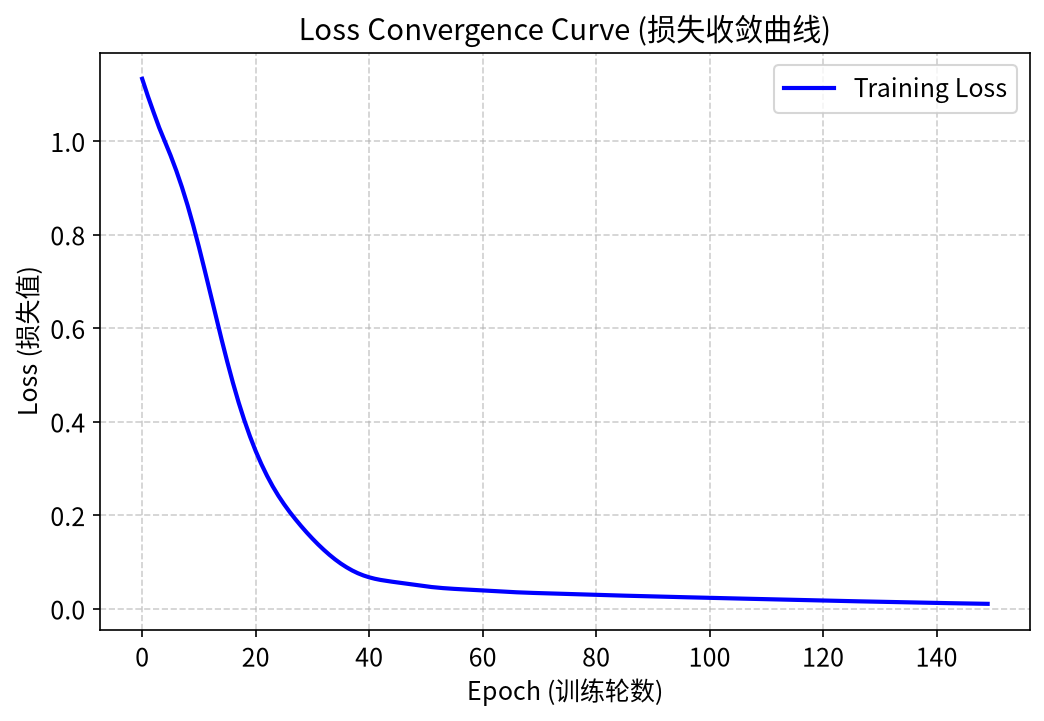

In [143]:
# 绘制loss曲线，查看收敛情况
plt.figure(figsize=(8, 5)) # 设置画布大小，宽8，高5
plt.plot(loss_history, label='Training Loss', color='blue', linewidth=2)

# 添加标签
plt.title('Loss Convergence Curve (损失收敛曲线)', fontsize=14)
plt.xlabel('Epoch (训练轮数)', fontsize=12)
plt.ylabel('Loss (损失值)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6) # 添加网格线，方便看数值
plt.legend(fontsize=12) # 显示图例

plt.show()

In [144]:
model.eval() # 将模型切换到测试状态

with torch.no_grad(): # 关闭梯度计算
    test_preds = model(test_X_tensor)
    test_loss = criterion(test_preds, test_y_tensor)
    predicted_classes = torch.argmax(test_preds, dim=1)
    correct = (predicted_classes == test_y_tensor).sum().item()

    total = test_y_tensor.size(0)
    accuracy = correct / total

print(f"测试集损失 (Test Loss): {test_loss.item():.4f}")
print(f"测试集准确率 (Test Accuracy): {accuracy * 100:.2f}%  ({correct}/{total})")

测试集损失 (Test Loss): 0.1356
测试集准确率 (Test Accuracy): 96.67%  (29/30)
